# Comparación de KNN, SVM y una red neuronal MLP
## Wisconsin Diagnostic Breast Cancer (WDBC)

**Objetivo:** clasificar tumores como **benignos (B)** o **malignos (M)**,
entrenar tres algoritmos sobre los mismos datos e interpretar sus diferencias.
La clase positiva será **maligno = 1**; benigno será **0**.

### Cómo ejecutarlo en Google Colab
1. Abre [Google Colab](https://colab.research.google.com/), selecciona
   **Archivo → Subir notebook** y elige este archivo `.ipynb`.
2. Selecciona **Entorno de ejecución → Ejecutar todas**. Una CPU es suficiente.
3. Consulta la tabla, las gráficas y las respuestas al final.

Este es un notebook **autocontenido**: incorpora una copia comprimida exacta de
`breast+cancer+wisconsin+diagnostic/wdbc.data`, el archivo proporcionado.
Si encuentra el archivo local, lo lee directamente. En Colab usa la copia incorporada;
no necesita subir datos, montar Drive ni descargar otro dataset.

**Protocolo fijado antes de evaluar:** una división estratificada 80/20, semilla 42,
el mismo preprocesamiento y los mismos pliegues de validación para los tres modelos.
Se ajustan hiperparámetros por **F1 de la clase maligna**, exclusivamente en entrenamiento.
El test se reserva para la comparación final. Las métricas de un test pequeño
son estimaciones del rendimiento, no una validación para uso clínico.


## 1. Bibliotecas y reproducibilidad

Colab normalmente incluye las bibliotecas necesarias. Esta celda instala únicamente
las que falten y muestra las versiones utilizadas. La semilla controla la división,
los pliegues y la inicialización de la MLP. Cambios de versión o de plataforma pueden
producir pequeñas variaciones numéricas; las conclusiones se calculan de nuevo al ejecutar.


In [1]:
import importlib.util
import subprocess
import sys

paquetes = {
    "numpy": "numpy", "pandas": "pandas",
    "matplotlib": "matplotlib", "sklearn": "scikit-learn",
    "IPython": "ipython",
}
faltantes = [paquete for modulo, paquete in paquetes.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *faltantes])

import base64
import gzip
import hashlib
from io import BytesIO
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython import get_ipython
from IPython.display import Markdown, display
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

SEMILLA = 42
FRACCION_TEST = 0.20
np.random.seed(SEMILLA)
pd.set_option("display.max_columns", 35)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

versiones = pd.Series({
    "Python": sys.version.split()[0], "NumPy": np.__version__,
    "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
    "Matplotlib": matplotlib.__version__,
}, name="Versión")
display(versiones.to_frame())


,Versión
Python,3.13.6
NumPy,2.5.4
pandas,3.1.1
scikit-learn,1.9.1
Matplotlib,3.11.2


## 2. Carga del dataset original

El archivo `wdbc.data` no tiene encabezado. Su esquema se toma del archivo
`wdbc.names` que acompaña a los datos: **ID**, **diagnóstico** y **30 variables
numéricas**. El ID identifica registros y no es una característica del tumor;
se excluirá del entrenamiento.

Las diez características básicas describen núcleos celulares de imágenes de una
punción aspirativa con aguja fina. Cada una aparece con tres resúmenes:
`mean` (media), `se` (error estándar) y `worst` (media de los tres valores mayores).
La siguiente celda contiene solamente la copia comprimida del archivo original;
puede permanecer contraída.


In [2]:
#@title Datos originales incorporados: ejecutar sin editar
DATOS_GZIP_BASE64 = (
    "..."
)
SHA256_ESPERADO = "d606af411f3e5be8a317a5a8b652b425aaf0ff38ca683d5327ffff94c3695f4a"


In [3]:
# Opcional: especifica la ruta al mismo wdbc.data. None permite detección automática.
RUTA_DATOS = None

if RUTA_DATOS is not None:
    ruta = Path(RUTA_DATOS).expanduser()
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe el archivo indicado: {ruta}")
else:
    candidatos = [
        Path("breast+cancer+wisconsin+diagnostic/wdbc.data"),
        Path("wisconsin/wdbc.data"), Path("wdbc.data"),
    ]
    ruta = next((p for p in candidatos if p.is_file()), None)

if ruta is not None:
    contenido = ruta.read_bytes()
    origen = str(ruta)
else:
    contenido = gzip.decompress(base64.b64decode(DATOS_GZIP_BASE64))
    origen = "Copia incorporada del wdbc.data original"

huella = hashlib.sha256(contenido).hexdigest()
assert huella == SHA256_ESPERADO, (
    "El archivo no coincide con el dataset original. Revisa RUTA_DATOS. "
    "Para usar la copia incorporada, retira de las rutas detectadas el archivo diferente."
)

caracteristicas_base = [
    "radius", "texture", "perimeter", "area", "smoothness",
    "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension",
]
columnas_entrada = [f"{nombre}_{resumen}"
                    for resumen in ("mean", "se", "worst")
                    for nombre in caracteristicas_base]
df = pd.read_csv(BytesIO(contenido), header=None, na_values=["?"])
assert df.shape[1] == 32, "Se esperaban 32 columnas sin encabezado."
df.columns = ["id", "diagnosis", *columnas_entrada]
assert df["diagnosis"].notna().all(), "La clase objetivo no admite faltantes."
assert set(df["diagnosis"].unique()) == {"B", "M"}, "Se esperaban las clases B y M."
df[columnas_entrada] = df[columnas_entrada].apply(pd.to_numeric, errors="raise")
assert not np.isinf(df[columnas_entrada].to_numpy()).any(), "Hay valores infinitos."

print(f"Origen: {origen}")
print(f"SHA-256: {huella}")
print(f"Registros: {len(df)} | Columnas originales: {df.shape[1]} | Entradas: {len(columnas_entrada)}")
display(df.head())


Origen: Copia incorporada del wdbc.data original
SHA-256: d606af411f3e5be8a317a5a8b652b425aaf0ff38ca683d5327ffff94c3695f4a
Registros: 569 | Columnas originales: 32 | Entradas: 30


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Exploración: registros, variables, clases y calidad

Primero se revisa el esquema, los valores faltantes, los duplicados y la distribución
de clases. La exploración descriptiva no ajusta transformaciones ni selecciona variables.
Todos los parámetros aprendidos se calcularán después usando únicamente entrenamiento.


,Descripción,Valor
0,Registros,569
1,Columnas originales,32
2,Características de entrada,30
3,Variable objetivo,diagnosis: B / M
4,Valores faltantes,0
5,IDs repetidos,0
6,Filas completas duplicadas,0
7,Variables constantes,0



Tipos de las columnas:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se 

,Diagnóstico,Registros,Porcentaje
0,Benigno (B = 0),357,62.74
1,Maligno (M = 1),212,37.26


,Característica,Significado
0,radius,Radio: distancia desde el centro al perímetro
1,texture,Textura: variación de los niveles de gris
2,perimeter,Perímetro del núcleo
3,area,Área del núcleo
4,smoothness,Suavidad: variación local de la longitud del r...
5,compactness,Compacidad: perímetro² / área − 1
6,concavity,Concavidad: intensidad de las partes cóncavas
7,concave_points,Puntos cóncavos del contorno
8,symmetry,Simetría
9,fractal_dimension,Dimensión fractal del contorno − 1


Las 30 columnas predictoras, en el orden del archivo:
radius_mean, texture_mean, perimeter_mean, area_mean, smoothness_mean, compactness_mean, concavity_mean, concave_points_mean, symmetry_mean, fractal_dimension_mean, radius_se, texture_se, perimeter_se, area_se, smoothness_se, compactness_se, concavity_se, concave_points_se, symmetry_se, fractal_dimension_se, radius_worst, texture_worst, perimeter_worst, area_worst, smoothness_worst, compactness_worst, concavity_worst, concave_points_worst, symmetry_worst, fractal_dimension_worst


,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.1273,3.5240,6.9810,11.7000,13.3700,15.7800,28.1100
texture_mean,569.0,19.2896,4.3010,9.7100,16.1700,18.8400,21.8000,39.2800
perimeter_mean,569.0,91.9690,24.2990,43.7900,75.1700,86.2400,104.1000,188.5000
area_mean,569.0,654.8891,351.9141,143.5000,420.3000,551.1000,782.7000,2501.0000
smoothness_mean,569.0,0.0964,0.0141,0.0526,0.0864,0.0959,0.1053,0.1634
compactness_mean,569.0,0.1043,0.0528,0.0194,0.0649,0.0926,0.1304,0.3454
concavity_mean,569.0,0.0888,0.0797,0.0000,0.0296,0.0615,0.1307,0.4268
concave_points_mean,569.0,0.0489,0.0388,0.0000,0.0203,0.0335,0.0740,0.2012
symmetry_mean,569.0,0.1812,0.0274,0.1060,0.1619,0.1792,0.1957,0.3040
fractal_dimension_mean,569.0,0.0628,0.0071,0.0500,0.0577,0.0615,0.0661,0.0974


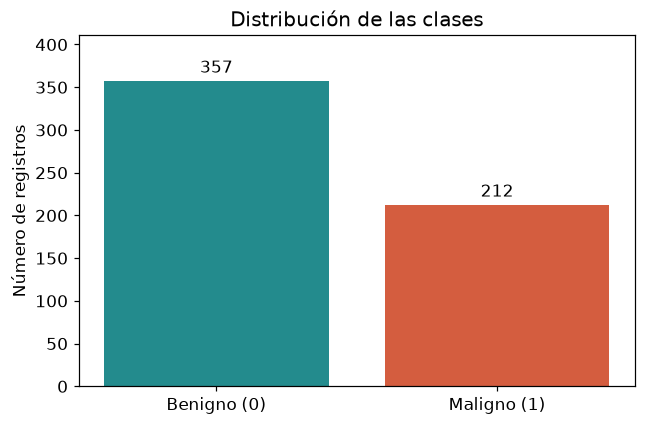

In [4]:
resumen_dataset = pd.DataFrame({
    "Descripción": ["Registros", "Columnas originales", "Características de entrada",
                    "Variable objetivo", "Valores faltantes", "IDs repetidos",
                    "Filas completas duplicadas", "Variables constantes"],
    "Valor": [len(df), df.shape[1], len(columnas_entrada), "diagnosis: B / M",
              int(df.isna().sum().sum()), int(df["id"].duplicated().sum()),
              int(df.duplicated().sum()), int((df[columnas_entrada].nunique() <= 1).sum())],
})
display(resumen_dataset)
print("\nTipos de las columnas:")
df.info()

conteo_clases = df["diagnosis"].value_counts().reindex(["B", "M"])
distribucion = pd.DataFrame({
    "Diagnóstico": ["Benigno (B = 0)", "Maligno (M = 1)"],
    "Registros": conteo_clases.to_numpy(),
    "Porcentaje": (100 * conteo_clases / len(df)).to_numpy(),
})
display(distribucion.round(2))

diccionario = pd.DataFrame({
    "Característica": caracteristicas_base,
    "Significado": [
        "Radio: distancia desde el centro al perímetro",
        "Textura: variación de los niveles de gris",
        "Perímetro del núcleo", "Área del núcleo",
        "Suavidad: variación local de la longitud del radio",
        "Compacidad: perímetro² / área − 1",
        "Concavidad: intensidad de las partes cóncavas",
        "Puntos cóncavos del contorno", "Simetría",
        "Dimensión fractal del contorno − 1",
    ],
})
display(diccionario)
print("Las 30 columnas predictoras, en el orden del archivo:")
print(", ".join(columnas_entrada))
display(df[columnas_entrada].describe().T.round(4))

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(["Benigno (0)", "Maligno (1)"], conteo_clases,
                color=["#238b8d", "#d45d3f"])
ax.bar_label(barras, padding=3)
ax.set(ylabel="Número de registros", title="Distribución de las clases")
ax.set_ylim(0, conteo_clases.max() * 1.15)
plt.tight_layout()
plt.show()


## 4. Separación de entradas, objetivo y conjuntos de datos

- **X:** las 30 características numéricas; se excluyen `id` y `diagnosis`.
- **y:** `diagnosis`, codificada como benigno = 0 y maligno = 1.
- **Entrenamiento:** 80 %. **Prueba:** 20 %.

Se realiza **una sola llamada a `train_test_split`**, con `stratify=y` para conservar
aproximadamente las proporciones de ambas clases. Los tres modelos recibirán las
mismas filas de entrenamiento y serán evaluados sobre las mismas filas de prueba.
No se balancean artificialmente las clases ni se modifica el conjunto de prueba.


In [5]:
X = df[columnas_entrada].copy()
y = df["diagnosis"].map({"B": 0, "M": 1}).astype("int64")
y.name = "maligno"

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=FRACCION_TEST, random_state=SEMILLA, stratify=y,
)

# Verificaciones de que no se mezclaron las filas de entrenamiento y prueba.
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(X)
assert X.shape[1] == 30 and "id" not in X.columns and "diagnosis" not in X.columns
assert df["id"].is_unique, "Revisar la división por grupos si existen IDs repetidos."

particiones = pd.DataFrame({
    nombre: {"Registros": len(objetivo), "Benignos (0)": int((objetivo == 0).sum()),
             "Malignos (1)": int((objetivo == 1).sum()),
             "% malignos": 100 * objetivo.mean()}
    for nombre, objetivo in [("Total", y), ("Entrenamiento", y_train), ("Prueba", y_test)]
}).T
display(particiones.round(2))
print(f"Forma de X_train: {X_train.shape}; forma de X_test: {X_test.shape}")
print("Referencia sin aprendizaje: predecir siempre la clase mayoritaria del entrenamiento.")
clase_mayoritaria = int(y_train.mode().iloc[0])
pred_base = np.full(len(y_test), clase_mayoritaria)
print(f"Accuracy de referencia: {accuracy_score(y_test, pred_base):.2%}")
print(f"Recall maligno de referencia: {recall_score(y_test, pred_base, zero_division=0):.2%}")


,Registros,Benignos (0),Malignos (1),% malignos
Total,569.0,357.0,212.0,37.26
Entrenamiento,455.0,285.0,170.0,37.36
Prueba,114.0,72.0,42.0,36.84


Forma de X_train: (455, 30); forma de X_test: (114, 30)
Referencia sin aprendizaje: predecir siempre la clase mayoritaria del entrenamiento.
Accuracy de referencia: 63.16%
Recall maligno de referencia: 0.00%


## 5. Preprocesamiento y definición de los tres modelos

Se usa un `Pipeline` independiente por algoritmo con estas etapas:

1. **Imputación por mediana** (`SimpleImputer`): el archivo original no tiene
   faltantes, por lo que aquí no cambia sus valores; se incluye como medida de robustez.
2. **Estandarización** (`StandardScaler`): $z_j=(x_j-\mu_j)/\sigma_j$.
   Evita que magnitudes grandes, como el área, dominen sobre otras pequeñas.
3. **Clasificador** KNN, SVM o MLP.

La escala importa en KNN por las distancias, en SVM por su margen y kernel, y en MLP
por la optimización de los pesos. El pipeline aprende las medianas, medias y
desviaciones **solo de las filas de entrenamiento de cada pliegue**, y luego aplica
esas transformaciones a la validación. En el ajuste final usa todo el entrenamiento;
el test solo recibe `predict`. Así se evita fuga de información.

| Modelo | Funcionamiento | Hiperparámetros explorados |
|---|---|---|
| KNN | Voto de vecinos según distancia euclídea | k = 3, 5, 7, 9; voto uniforme o por distancia |
| SVM | Frontera de máximo margen con kernel radial RBF | C = 0.1, 1, 10; gamma = `scale` o 0.01 |
| MLP | Red densa con activación ReLU y salida binaria | Capas (16,) o (32, 16); alpha = 0.0001 o 0.01 |

La MLP utiliza L-BFGS, apropiado para entrenar una red pequeña en este conjunto de
datos tabular, con hasta 2000 iteraciones. Las tres familias aprenden relaciones no
lineales. No se presupone que una arquitectura más compleja produzca mejores resultados.


In [6]:
def construir_pipeline(clasificador):
    return Pipeline([
        ("imputacion", SimpleImputer(strategy="median")),
        ("estandarizacion", StandardScaler()),
        ("modelo", clasificador),
    ])

configuraciones = {
    "KNN": {
        "pipeline": construir_pipeline(KNeighborsClassifier(metric="minkowski", p=2)),
        "parametros": {
            "modelo__n_neighbors": [3, 5, 7, 9],
            "modelo__weights": ["uniform", "distance"],
        },
    },
    "SVM": {
        "pipeline": construir_pipeline(SVC(kernel="rbf")),
        "parametros": {
            "modelo__C": [0.1, 1.0, 10.0],
            "modelo__gamma": ["scale", 0.01],
        },
    },
    "MLP": {
        "pipeline": construir_pipeline(MLPClassifier(
            activation="relu", solver="lbfgs", max_iter=2000,
            max_fun=50000, random_state=SEMILLA,
        )),
        "parametros": {
            "modelo__hidden_layer_sizes": [(16,), (32, 16)],
            "modelo__alpha": [0.0001, 0.01],
        },
    },
}

# Se materializan una sola vez: todos los algoritmos usan los mismos cinco pliegues.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
pliegues_cv = list(cv.split(X_train, y_train))
for idx_train, idx_val in pliegues_cv:
    assert set(idx_train).isdisjoint(idx_val)
    assert len(idx_train) + len(idx_val) == len(X_train)

print("Tres pipelines independientes; cinco pliegues idénticos y solo de entrenamiento.")


Tres pipelines independientes; cinco pliegues idénticos y solo de entrenamiento.


## 6. Entrenamiento y selección de hiperparámetros

`GridSearchCV` compara las combinaciones con los mismos cinco pliegues estratificados.
El criterio principal es **F1 de malignos**, que combina precisión y recall.
También se registra el recall para poder examinar la detección de malignos.
Se elige la mejor configuración de cada familia y se reentrena con todo `X_train`.

El F1 de validación y su desviación estándar se mostrarán separados de las métricas
de prueba. La desviación entre pliegues describe variabilidad; no es un intervalo
de confianza. Este experimento compara rejillas pequeñas, sin pretender explorar
todas las configuraciones posibles. Una advertencia de convergencia de la MLP debe
revisarse; no se silencian las advertencias.


In [7]:
busquedas = {}
filas_cv = []
for nombre, configuracion in configuraciones.items():
    print(f"Entrenando {nombre}...", flush=True)
    busqueda = GridSearchCV(
        estimator=configuracion["pipeline"],
        param_grid=configuracion["parametros"],
        scoring={"f1": "f1", "recall": "recall", "accuracy": "accuracy"},
        refit="f1", cv=pliegues_cv, n_jobs=1, error_score="raise",
    )
    # Limita hilos BLAS para que una red tan pequeña no incurra en sobrecosto.
    with threadpool_limits(limits=1):
        busqueda.fit(X_train, y_train)
    busquedas[nombre] = busqueda
    i = busqueda.best_index_
    filas_cv.append({
        "Modelo": nombre,
        "F1 CV medio": busqueda.best_score_,
        "Desv. F1 CV": busqueda.cv_results_["std_test_f1"][i],
        "Recall CV medio": busqueda.cv_results_["mean_test_recall"][i],
        "Accuracy CV medio": busqueda.cv_results_["mean_test_accuracy"][i],
        "Mejores parámetros": str({k.replace("modelo__", ""): v
                                  for k, v in busqueda.best_params_.items()}),
    })

tabla_cv = pd.DataFrame(filas_cv).set_index("Modelo")
display(tabla_cv.round(4))

# Esta recomendación se fija sin consultar el test.
orden_cv = tabla_cv.sort_values(
    ["F1 CV medio", "Recall CV medio"], ascending=False, kind="stable",
)
candidato_cv = orden_cv.index[0]
print(f"Candidato seleccionado solo con entrenamiento: {candidato_cv}.")
print("Criterio: mayor F1 CV; desempate por recall CV y, si persiste, orden KNN/SVM/MLP.")
mlp_final = busquedas["MLP"].best_estimator_.named_steps["modelo"]
print(f"MLP elegida: {mlp_final.hidden_layer_sizes}; iteraciones: {mlp_final.n_iter_}; "
      f"pérdida final de entrenamiento: {mlp_final.loss_:.6f}")


Entrenando KNN...


Entrenando SVM...


Entrenando MLP...


,F1 CV medio,Desv. F1 CV,Recall CV medio,Accuracy CV medio,Mejores parámetros
Modelo,,,,,
KNN,0.9633,0.0250,0.9353,0.9736,"{'n_neighbors': 3, 'weights': 'uniform'}"
SVM,0.9674,0.0114,0.9647,0.9758,"{'C': 10.0, 'gamma': 'scale'}"
MLP,0.9618,0.0123,0.9647,0.9714,"{'alpha': 0.01, 'hidden_layer_sizes': (16,)}"


Candidato seleccionado solo con entrenamiento: SVM.
Criterio: mayor F1 CV; desempate por recall CV y, si persiste, orden KNN/SVM/MLP.
MLP elegida: (16,); iteraciones: 48; pérdida final de entrenamiento: 0.001550


## 7. Evaluación sobre el mismo conjunto de prueba

Cada modelo predice una vez sobre `X_test`. Para las métricas binarias,
**positivo = maligno = 1**:

- **TP:** maligno correctamente detectado.
- **TN:** benigno correctamente clasificado.
- **FP:** benigno clasificado como maligno, una falsa alarma.
- **FN:** maligno clasificado como benigno, un caso maligno omitido.

$$\mathrm{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}$$
$$\mathrm{Precision}=\frac{TP}{TP+FP},\qquad
\mathrm{Recall}=\frac{TP}{TP+FN},\qquad
F1=\frac{2\,\mathrm{Precision}\,\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}$$

El recall es la **sensibilidad para detectar malignos**. También se calcula la
especificidad, $TN/(TN+FP)$, para describir la detección de benignos. Todas las
métricas de la tabla están en escala 0–1; las gráficas las muestran como porcentajes.


In [8]:
predicciones = {}
matrices = {}
filas_resultados = []
for nombre, busqueda in busquedas.items():
    y_pred = busqueda.best_estimator_.predict(X_test)
    predicciones[nombre] = y_pred
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    matrices[nombre] = cm
    tn, fp, fn, tp = cm.ravel()
    filas_resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Especificidad": tn / (tn + fp),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Errores": int(fp + fn),
    })
    assert len(y_pred) == len(y_test) and cm.sum() == len(y_test)

resultados = pd.DataFrame(filas_resultados).set_index("Modelo")
metricas = ["Accuracy", "Precision", "Recall", "F1-score"]
assert ((resultados[metricas] >= 0) & (resultados[metricas] <= 1)).all().all()
assert np.allclose(resultados["Accuracy"], 1 - resultados["Errores"] / len(y_test))

print(f"Comparación final: los mismos {len(y_test)} registros de prueba en los tres casos.")
display(resultados.round(4))
print("Precision, Recall y F1-score corresponden a la clase maligna (1).")

for nombre, y_pred in predicciones.items():
    print(f"\n{'=' * 18} {nombre} {'=' * 18}")
    print(classification_report(
        y_test, y_pred, labels=[0, 1],
        target_names=["Benigno (0)", "Maligno (1)"], digits=4, zero_division=0,
    ))


Comparación final: los mismos 114 registros de prueba en los tres casos.


,Accuracy,Precision,Recall,F1-score,Especificidad,TN,FP,FN,TP,Errores
Modelo,,,,,,,,,,
KNN,0.9386,0.9730,0.8571,0.9114,0.9861,71,1,6,36,7
SVM,0.9737,1.0000,0.9286,0.9630,1.0000,72,0,3,39,3
MLP,0.9737,0.9756,0.9524,0.9639,0.9861,71,1,2,40,3


Precision, Recall y F1-score corresponden a la clase maligna (1).

================== KNN ==================
              precision    recall  f1-score   support

 Benigno (0)     0.9221    0.9861    0.9530        72
 Maligno (1)     0.9730    0.8571    0.9114        42

    accuracy                         0.9386       114
   macro avg     0.9475    0.9216    0.9322       114
weighted avg     0.9408    0.9386    0.9377       114


================== SVM ==================
              precision    recall  f1-score   support

 Benigno (0)     0.9600    1.0000    0.9796        72
 Maligno (1)     1.0000    0.9286    0.9630        42

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114


================== MLP ==================
              precision    recall  f1-score   support

 Benigno (0)     0.9726    0.9861    0.9793        72
 Maligno (1)     0.9756    0.9524    0.963

## 8. Matrices de confusión y gráficas comparativas

En cada matriz, las **filas son la clase real** y las **columnas la predicción**.
El orden es `[benigno, maligno]`, por lo que la matriz es `[[TN, FP], [FN, TP]]`.
La celda inferior izquierda identifica los malignos clasificados como benignos.
Se utiliza la misma escala de color para que las tres matrices sean comparables.


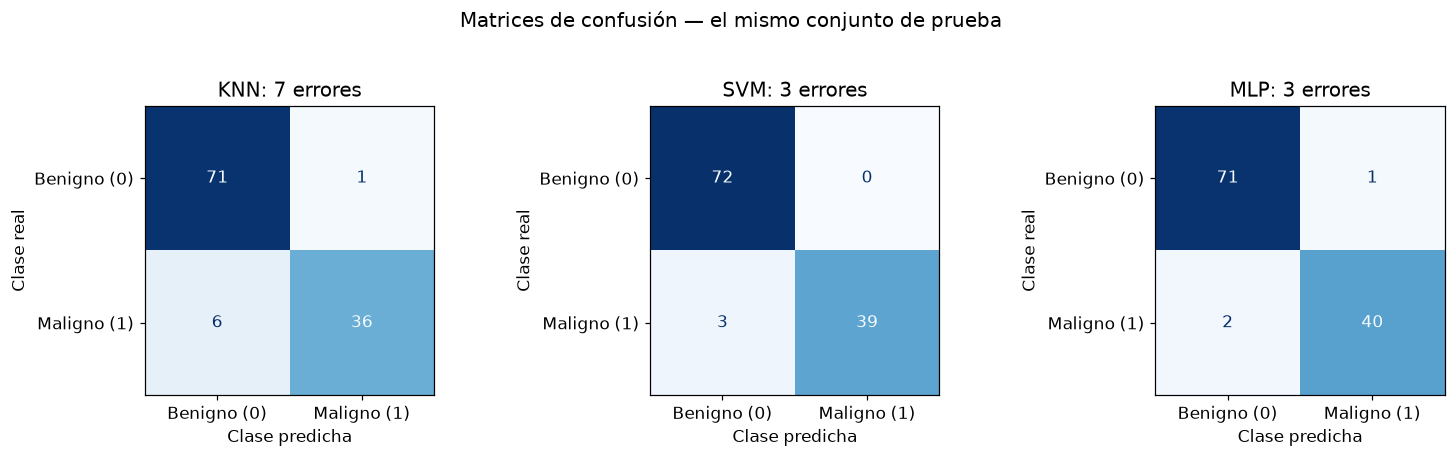

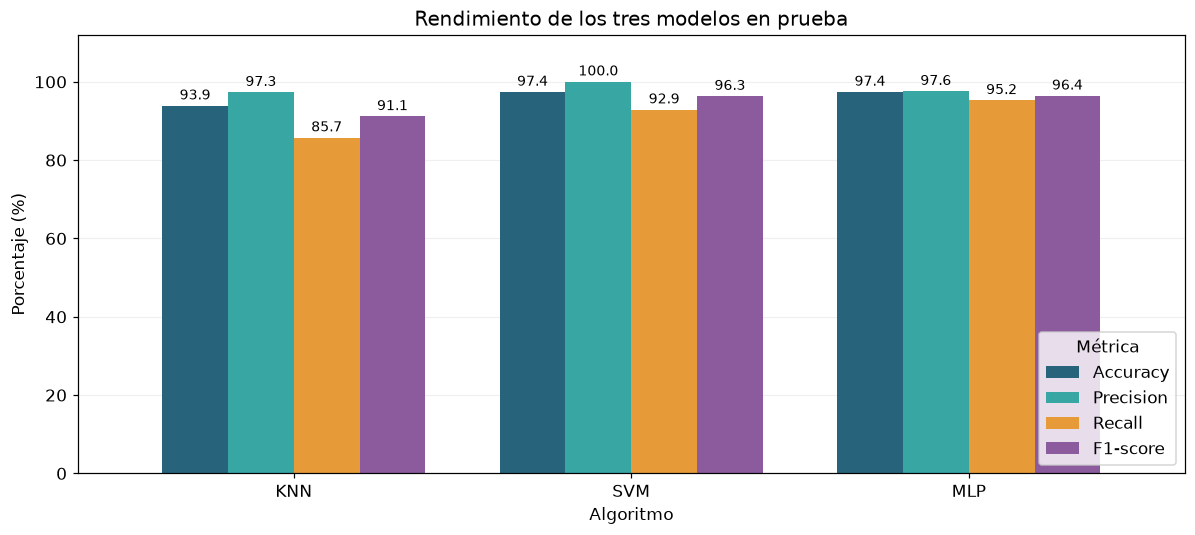

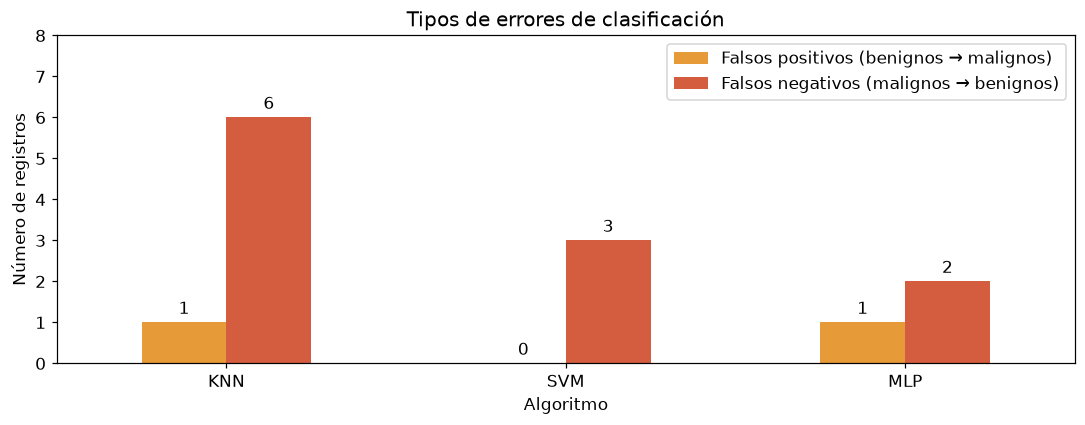

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
maximo = max(cm.max() for cm in matrices.values())
for ax, (nombre, cm) in zip(axes, matrices.items()):
    disp = ConfusionMatrixDisplay(cm, display_labels=["Benigno (0)", "Maligno (1)"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d",
              im_kw={"vmin": 0, "vmax": maximo})
    ax.set_title(f"{nombre}: {resultados.loc[nombre, 'Errores']:.0f} errores")
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
fig.suptitle("Matrices de confusión — el mismo conjunto de prueba", y=1.03)
plt.tight_layout()
plt.show()

ax = (resultados[metricas] * 100).plot.bar(
    figsize=(11, 5), rot=0, width=0.78,
    color=["#27647b", "#38a6a3", "#e69b38", "#8b5b9e"],
)
ax.set(title="Rendimiento de los tres modelos en prueba",
       ylabel="Porcentaje (%)", xlabel="Algoritmo", ylim=(0, 112))
ax.legend(title="Métrica", loc="lower right")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.1f", padding=2, fontsize=9)
plt.tight_layout()
plt.show()

ax = resultados[["FP", "FN"]].rename(columns={
    "FP": "Falsos positivos (benignos → malignos)",
    "FN": "Falsos negativos (malignos → benignos)",
}).plot.bar(figsize=(10, 4), rot=0, color=["#e69b38", "#d45d3f"])
ax.set(title="Tipos de errores de clasificación", ylabel="Número de registros", xlabel="Algoritmo")
ax.set_ylim(0, max(1, int(resultados[["FP", "FN"]].to_numpy().max())) + 2)
ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
ax.legend(loc="upper right")
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.0f", padding=3)
plt.tight_layout()
plt.show()


## 9. Interpretación y respuestas basadas en los resultados

Las respuestas siguientes se generan a partir de las métricas efectivamente
obtenidas. Para “mejor rendimiento” se usa **F1 maligno** como criterio principal,
tal como se fijó antes de entrenar. Se informa también quién lidera en accuracy y
recall; pueden ser modelos distintos o existir empates. El liderazgo en test es
descriptivo: no se reutiliza este test para ajustar modelos ni sus umbrales.


In [10]:
def nombres_extremos(columna, maximizar=True):
    valores = resultados[columna]
    extremo = valores.max() if maximizar else valores.min()
    return ", ".join(valores.index[np.isclose(valores, extremo, rtol=0, atol=1e-12)])

mejor_f1 = nombres_extremos("F1-score")
mejor_accuracy = nombres_extremos("Accuracy")
mejor_recall = nombres_extremos("Recall")
mas_errores = nombres_extremos("Errores")
menos_fn = nombres_extremos("FN", maximizar=False)
n_malignos = int((y_test == 1).sum())
n_benignos = int((y_test == 0).sum())

display(Markdown(f"""
### ¿Cuál de los tres algoritmos obtuvo el mejor rendimiento?

Con el criterio principal definido, **{mejor_f1}** obtiene el mayor F1 de malignos:
**{resultados['F1-score'].max():.4f}**. La mayor exactitud corresponde a
**{mejor_accuracy}**, con **{resultados['Accuracy'].max():.2%}**, y el mayor recall
maligno a **{mejor_recall}**, con **{resultados['Recall'].max():.2%}**.
Si aparecen varios nombres, existe un empate en esa métrica.

La selección hecha **sin consultar prueba** fue **{candidato_cv}**, con F1 medio
de validación cruzada **{tabla_cv.loc[candidato_cv, 'F1 CV medio']:.4f}**.
Un ganador distinto en test refleja variación entre muestras y no autoriza a
reajustar con este mismo conjunto de prueba. Los resultados dependen de esta
partición y de las rejillas de hiperparámetros exploradas.

### ¿Cuál presentó más errores de clasificación?

**{mas_errores}** acumula el mayor número de errores:
**{int(resultados['Errores'].max())} de {len(y_test)} registros**.
Prueba contiene **{n_benignos} benignos** y **{n_malignos} malignos**.
El total de errores es **FP + FN**; la matriz distingue la gravedad de cada tipo.
"""))

display(Markdown("### ¿Qué diferencias se observaron en su comportamiento?"))
explicaciones = {
    "KNN": "Decide por similitud con vecinos. Su resultado depende de la escala, "
           "el número de vecinos y la densidad local de los datos.",
    "SVM": "El kernel RBF permite una frontera no lineal. C controla la penalización "
           "de errores y gamma el alcance de cada observación.",
    "MLP": "Aprende representaciones no lineales mediante capas de neuronas. "
           "Depende de su arquitectura, regularización e inicialización; su complejidad "
           "no garantiza una ventaja en un dataset pequeño.",
}
for nombre, fila in resultados.iterrows():
    display(Markdown(
        f"- **{nombre}:** accuracy **{fila['Accuracy']:.2%}**, precisión maligna "
        f"**{fila['Precision']:.2%}**, recall **{fila['Recall']:.2%}** y F1 "
        f"**{fila['F1-score']:.4f}**. Omitió **{int(fila['FN'])} de {n_malignos} "
        f"malignos** (FN); falsas alarmas (FP): **{int(fila['FP'])}**. "
        + explicaciones[nombre]
    ))

comparacion = resultados.loc[["SVM", "MLP"]]
if (np.isclose(comparacion.loc["SVM", "Accuracy"], comparacion.loc["MLP", "Accuracy"])
        and comparacion.loc["SVM", "FN"] != comparacion.loc["MLP", "FN"]):
    mas_sensible = comparacion["FN"].idxmin()
    display(Markdown(
        f"**SVM y MLP alcanzan la misma accuracy**, con "
        f"**{int(comparacion.loc['SVM', 'Errores'])} errores cada uno**, "
        f"pero **{mas_sensible} detecta más malignos a cambio de más falsas alarmas**. "
        "Este resultado muestra por qué el total de aciertos no describe "
        "por completo el comportamiento en esta clasificación."
    ))

diferencia_accuracy = resultados["Accuracy"].max() - resultados["Accuracy"].min()
diferencia_recall = resultados["Recall"].max() - resultados["Recall"].min()
aciertos_conjuntos = pd.DataFrame(
    {nombre: pred == y_test.to_numpy() for nombre, pred in predicciones.items()},
    index=y_test.index,
)
omisiones = pd.DataFrame(
    {nombre: (pred == 0) & (y_test.to_numpy() == 1)
     for nombre, pred in predicciones.items()},
    index=y_test.index,
)
malignos_omitidos_por_todos = int(omisiones.all(axis=1).sum())
display(Markdown(f"""
La distancia entre la mejor y la peor accuracy es de **{100 * diferencia_accuracy:.2f}
puntos porcentuales**, y entre los recalls es de **{100 * diferencia_recall:.2f} puntos**.
Los tres modelos aciertan simultáneamente en **{int(aciertos_conjuntos.all(axis=1).sum())}
registros**. El número de malignos omitidos por los tres es **{malignos_omitidos_por_todos}**.
En este test, **un solo error modifica la accuracy en {100 / len(y_test):.2f} puntos**;
un maligno adicional omitido cambia el recall en **{100 / n_malignos:.2f} puntos**.
Por ello, diferencias pequeñas no demuestran por sí solas superioridad general.
Las explicaciones de cada algoritmo describen su mecanismo; esta comparación
no aísla causalmente el motivo de cada error.

### ¿Elegirías el algoritmo con mayor exactitud para este problema?

**No usaría únicamente la exactitud para decidir.** Esta clasificación distingue
tumores benignos y malignos. Un **falso negativo** clasifica un tumor maligno
como benigno y puede retrasar su evaluación. Un falso positivo también tiene
consecuencias, como estudios adicionales y preocupación, pero ambos errores
no necesariamente tienen el mismo costo.

En este experimento, **{menos_fn}** presenta el menor número de falsos negativos
(**{int(resultados['FN'].min())}**); el máximo de accuracy corresponde a
**{mejor_accuracy}**. Estos resultados deben leerse juntos. En una selección orientada a
detectar malignos priorizaría un **recall suficientemente alto**, revisaría los
FN y después compararía precisión, especificidad y F1 para controlar falsas
alarmas. El F1 usado aquí es un compromiso general; no asigna por sí mismo un
costo clínico mayor a los FN.

Mi candidato inicial según el protocolo es **{candidato_cv}**, elegido con
validación de entrenamiento. Antes de elegir un modelo para esta finalidad,
definiría el recall mínimo y los costos de FP/FN con quienes lo utilizarían.
Compararía los modelos con ese criterio y, si fuera necesario, ajustaría
hiperparámetros, pesos o umbrales **con validación**, nunca reutilizando este test.
Después comprobaría el resultado en datos independientes y representativos.
Este ejercicio permite comparar algoritmos; no establece su aptitud clínica.
"""))



### ¿Cuál de los tres algoritmos obtuvo el mejor rendimiento?

Con el criterio principal definido, **MLP** obtiene el mayor F1 de malignos:
**0.9639**. La mayor exactitud corresponde a
**SVM, MLP**, con **97.37%**, y el mayor recall
maligno a **MLP**, con **95.24%**.
Si aparecen varios nombres, existe un empate en esa métrica.

La selección hecha **sin consultar prueba** fue **SVM**, con F1 medio
de validación cruzada **0.9674**.
Un ganador distinto en test refleja variación entre muestras y no autoriza a
reajustar con este mismo conjunto de prueba. Los resultados dependen de esta
partición y de las rejillas de hiperparámetros exploradas.

### ¿Cuál presentó más errores de clasificación?

**KNN** acumula el mayor número de errores:
**7 de 114 registros**.
Prueba contiene **72 benignos** y **42 malignos**.
El total de errores es **FP + FN**; la matriz distingue la gravedad de cada tipo.


### ¿Qué diferencias se observaron en su comportamiento?

- **KNN:** accuracy **93.86%**, precisión maligna **97.30%**, recall **85.71%** y F1 **0.9114**. Omitió **6 de 42 malignos** (FN); falsas alarmas (FP): **1**. Decide por similitud con vecinos. Su resultado depende de la escala, el número de vecinos y la densidad local de los datos.

- **SVM:** accuracy **97.37%**, precisión maligna **100.00%**, recall **92.86%** y F1 **0.9630**. Omitió **3 de 42 malignos** (FN); falsas alarmas (FP): **0**. El kernel RBF permite una frontera no lineal. C controla la penalización de errores y gamma el alcance de cada observación.

- **MLP:** accuracy **97.37%**, precisión maligna **97.56%**, recall **95.24%** y F1 **0.9639**. Omitió **2 de 42 malignos** (FN); falsas alarmas (FP): **1**. Aprende representaciones no lineales mediante capas de neuronas. Depende de su arquitectura, regularización e inicialización; su complejidad no garantiza una ventaja en un dataset pequeño.

**SVM y MLP alcanzan la misma accuracy**, con **3 errores cada uno**, pero **MLP detecta más malignos a cambio de más falsas alarmas**. Este resultado muestra por qué el total de aciertos no describe por completo el comportamiento en esta clasificación.


La distancia entre la mejor y la peor accuracy es de **3.51
puntos porcentuales**, y entre los recalls es de **9.52 puntos**.
Los tres modelos aciertan simultáneamente en **105
registros**. El número de malignos omitidos por los tres es **1**.
En este test, **un solo error modifica la accuracy en 0.88 puntos**;
un maligno adicional omitido cambia el recall en **2.38 puntos**.
Por ello, diferencias pequeñas no demuestran por sí solas superioridad general.
Las explicaciones de cada algoritmo describen su mecanismo; esta comparación
no aísla causalmente el motivo de cada error.

### ¿Elegirías el algoritmo con mayor exactitud para este problema?

**No usaría únicamente la exactitud para decidir.** Esta clasificación distingue
tumores benignos y malignos. Un **falso negativo** clasifica un tumor maligno
como benigno y puede retrasar su evaluación. Un falso positivo también tiene
consecuencias, como estudios adicionales y preocupación, pero ambos errores
no necesariamente tienen el mismo costo.

En este experimento, **MLP** presenta el menor número de falsos negativos
(**2**); el máximo de accuracy corresponde a
**SVM, MLP**. Estos resultados deben leerse juntos. En una selección orientada a
detectar malignos priorizaría un **recall suficientemente alto**, revisaría los
FN y después compararía precisión, especificidad y F1 para controlar falsas
alarmas. El F1 usado aquí es un compromiso general; no asigna por sí mismo un
costo clínico mayor a los FN.

Mi candidato inicial según el protocolo es **SVM**, elegido con
validación de entrenamiento. Antes de elegir un modelo para esta finalidad,
definiría el recall mínimo y los costos de FP/FN con quienes lo utilizarían.
Compararía los modelos con ese criterio y, si fuera necesario, ajustaría
hiperparámetros, pesos o umbrales **con validación**, nunca reutilizando este test.
Después comprobaría el resultado en datos independientes y representativos.
Este ejercicio permite comparar algoritmos; no establece su aptitud clínica.


## 10. Límites y trazabilidad del experimento

- Se comparan tres familias con todas las variables originales y un test estratificado
  común. No se aplica selección de variables ni transformación ajustada antes de dividir.
- La validación cruzada se utiliza para seleccionar configuraciones dentro de entrenamiento.
  Sus mejores puntuaciones pueden ser optimistas por la propia búsqueda; el test reservado
  ofrece una evaluación separada. No se afirma significancia estadística de las diferencias.
- Una única división de 569 registros no describe toda la variabilidad posible.
  Una evaluación más amplia puede usar validación cruzada anidada o repetida y un
  conjunto externo, sin optimizar sobre los resultados del test actual.
- El dataset describe mediciones de imágenes de núcleos celulares. No representa por sí
  solo todos los escenarios de detección de cáncer ni todas las poblaciones.
- **Fuente usada para los datos y su esquema:** archivos locales `wdbc.data` y
  `wdbc.names`, de Wisconsin Diagnostic Breast Cancer. Autores indicados en `wdbc.names`:
  W. H. Wolberg, W. N. Street y O. L. Mangasarian. La huella SHA-256 de carga comprueba
  que los datos incorporados son idénticos al archivo proporcionado.

El notebook conserva sus salidas de ejecución: tabla comparativa, reportes por clase,
matrices de confusión, gráficas e interpretación. Al ejecutar todas las celdas,
esas salidas y las respuestas se regeneran con los datos y el entorno utilizados.
